# Analysis 5 — Ten-Seed Predictive-Stability Confirmation (LSTM vs TFT)

**Why this notebook exists.** An audit of `main.tex` found that the TFT
top-5 confirmation figures cited in the model-selection paragraph (19.06%
+/- 1.45% and 17.79% +/- 1.58%, "two independent confirmation sessions")
were never computed by any script — they traced to a hand-typed
comment/print string with no backing artefact. Three genuine reruns
produced rank-2 means of 18.82%, 18.70%, and 20.07%, a 1.37 percentage
point spread on a nominally fixed configuration.

A follow-up methodology check found that this same 1.37pp confirmation
noise is roughly the same magnitude as the ~1.50pp predictive-spread
figure used to argue the TFT is the *more stable* architecture (the
"dissociation" claim: TFT more stable predictively, less stable
attributionally). With n=3 seeds per architecture, no variance-equality
test has power to support that comparison, and the literature (Colas et
al. 2018; Reimers & Gurevych 2017; Henderson et al. 2018) treats 3 seeds
as insufficient for any seed-variance claim.

**What this notebook does.** Trains 10 independent seeds each for the
LSTM and the TFT (same selected config: d_model=64, n_heads=4,
dropout=0.2, lstm_units=(64,32), batch_size=64), on the anchor building,
under the SAME protocol as the original 3-seed runs. Then runs the
statistical tests the methodology check specified: Levene's test (and
Brown-Forsythe) for variance equality, Welch's t-test for mean
difference, on the PREDICTIVE side. A parallel attribution-stability
metric (coefficient of variation of permutation importance across seeds)
is computed for both architectures so the two halves of the dissociation
claim are tested on equal footing.

**Provenance discipline — read before running.**
- This is a SEPARATE analysis (`analysis5_*` filenames throughout) from
  the existing Analysis 1/3/4 archives. It does NOT touch, overwrite, or
  invalidate `lstm_draw1.keras` or any of the six existing draw models —
  those remain the sole basis for every reported attribution-robustness
  finding (SS000, the method-effect ordering, the ss2 correction). This
  notebook trains TEN NEW models per architecture purely to test the
  predictive/attribution-stability dissociation claim.
- Run on the GPU (4070 Super) machine, in the existing `fyp_env`.
- Incremental CSV saves after every seed (not just every architecture) so
  a crash loses at most one training run, matching the WSL2 crash-recovery
  convention from Analysis 1.
- Seeds are fixed and logged: 2016-2025 (10 seeds), so the first three
  seeds recreate a superset check against the ORIGINAL 3-seed LSTM figures
  (2016, 2017, 2018) — if the LSTM's seed-1..3 subset here doesn't
  approximately match the original 5.97pp spread, that is itself worth
  flagging before trusting the full 10-seed result.
- GPU training is NOT bit-deterministic even with a fixed seed (documented
  in the original project: run 1 reproduces, runs 2-3 drift). This is
  expected and is the entire point of a multi-seed protocol — do not
  attempt to force determinism.


## Cell 0 — Imports and GPU memory config (MUST run first, before any TF import)

In [2]:
import os, sys, gc, json, time, hashlib
import numpy as np
import pandas as pd
import tensorflow as tf
from scipy.stats import levene, ttest_ind
from pathlib import Path

# GPU memory growth MUST be set before any other TF/SHAP import touches the GPU.
gpus = tf.config.list_physical_devices('GPU')
for g in gpus:
    tf.config.experimental.set_memory_growth(g, True)
print(f"GPUs visible: {gpus}")

sys.path.insert(0, '/home/pie/fyp/phase2')
from fyp_pipeline import prepare_building, align_to_schema, split_sequences, WINDOW_SIZE

PHASE2_DIR = '/home/pie/fyp/phase2'
RESULTS_DIR = os.path.join(PHASE2_DIR, 'results')
os.makedirs(RESULTS_DIR, exist_ok=True)

ANCHOR = 'Bobcat_education_Alissa'
N_SEEDS = 10
SEEDS = list(range(2016, 2016 + N_SEEDS))   # 2016..2025 — first 3 match the original LSTM seeds exactly
print(f"Seeds ({N_SEEDS}): {SEEDS}")

# TFT_CONFIG is defined in Cell 2 (architecture cell) below, after


GPUs visible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Seeds (10): [2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]


## Cell 1 — Load anchor data once

Prepared once, reused across all 20 training runs (10 LSTM + 10 TFT). This
matches the original protocol: same data, same split, only the
initialisation seed varies.


In [3]:
# ── Paths — matches FYP_Phase2_TFT_FINAL.ipynb cell [1]/[14] exactly ────
PHASE1_DIR = '/home/pie/fyp/ZEIT4500 - FYP'
DATA_DIR   = os.path.join(PHASE1_DIR, 'Data')   # capital D — confirmed via find

elec_path   = os.path.join(DATA_DIR, 'electricity.csv')
electricity = pd.read_csv(elec_path, parse_dates=['timestamp'])
print(f"Electricity   : {electricity.shape}")

wx_path     = os.path.join(DATA_DIR, 'weather.csv')
weather_all = pd.read_csv(wx_path, parse_dates=['timestamp'])
print(f"Weather       : {weather_all.shape}")

METER_FILES = {
    'gas': 'gas.csv', 'hotwater': 'hotwater.csv', 'chilledwater': 'chilledwater.csv',
    'steam': 'steam.csv', 'solar': 'solar.csv', 'water': 'water.csv', 'irrigation': 'irrigation.csv',
}
meter_dfs = {}
for name, fname in METER_FILES.items():
    path = os.path.join(DATA_DIR, fname)
    if os.path.exists(path):
        meter_dfs[name] = pd.read_csv(path, parse_dates=['timestamp'])
print(f"Meters loaded : {sorted(meter_dfs.keys())}")

# ── Prepare the anchor's sequences ONCE, reused across all 20 runs ─────
# NOTE: prepare_building() returns raw_y_mean, NOT a split index -- the
# actual train/val/test split is a SEPARATE call to split_sequences(),
# which returns SIX arrays. This matches the real pipeline signature,
# not the two-way split my first draft of this cell assumed.
X_seq, y_seq, scaler_y, feature_cols, raw_y_mean = prepare_building(
    ANCHOR, electricity, weather_all, meter_dfs)
print(f"Feature schema ({len(feature_cols)}): {feature_cols}")
print(f"Raw mean consumption: {raw_y_mean:.2f} kWh")

X_train, y_train, X_val, y_val, X_test, y_test = split_sequences(
    X_seq, y_seq, train_frac=0.80, val_frac=0.10)
print(f"Train: {X_train.shape}  Val: {X_val.shape}  Test: {X_test.shape}")

N_ANCHOR_FEATURES = X_train.shape[-1]
ANCHOR_FEATURE_SCHEMA = feature_cols   # same name used by permutation helpers below

# test-partition mean |y|, in kWh -- the denominator for anchor MAE%,
# matching the 17.3% convention used throughout the project (test
# partition, NOT full-year).
y_test_true = scaler_y.inverse_transform(y_test.reshape(-1, 1))
y_test_mean = float(np.abs(y_test_true).mean())
print(f"n_features = {N_ANCHOR_FEATURES}")
print(f"test-partition mean |y| = {y_test_mean:.3f}  (denominator for anchor MAE%%)")


Electricity   : (17544, 1579)
Weather       : (331166, 10)
Meters loaded : ['chilledwater', 'gas', 'hotwater', 'irrigation', 'solar', 'steam', 'water']
Feature schema (15): ['airTemperature', 'dewTemperature', 'windDirection', 'windSpeed', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'month_sin', 'month_cos', 'is_weekend', 'chilledwater', 'gas', 'hotwater', 'solar']
Raw mean consumption: 61.79 kWh
Train: (6988, 48, 15)  Val: (874, 48, 15)  Test: (874, 48, 15)
n_features = 15
test-partition mean |y| = 61.645  (denominator for anchor MAE%%)


## Cell 2 — Model builders (LSTM and TFT), UNCHANGED architecture

Copy these from the original notebook's model-definition cells so the
architecture is byte-identical to what produced the original results. The
ONLY thing that should vary across runs is the initialisation seed.


In [4]:
from tensorflow.keras import layers

# ── Pasted verbatim from FYP_Phase2_TFT_FINAL.ipynb cells [5],[7],[9],[11],[13] ──
# Architecture MUST be byte-identical to what produced the original grid-search
# and confirmation results. Do not modify.

class GRN(layers.Layer):
    """Gated Residual Network — TFT's core building block (Lim et al. 2021, eq. 2-5)."""
    def __init__(self, units, dropout=0.1, **kwargs):
        super().__init__(**kwargs)
        self.units = units
        self.dense1 = layers.Dense(units, activation='elu')
        self.dense2 = layers.Dense(units)
        self.gate_dense = layers.Dense(units * 2)  # for GLU
        self.dropout = layers.Dropout(dropout)
        self.layernorm = layers.LayerNormalization()
        self.skip_proj = None  # built lazily if input dim != units

    def build(self, input_shape):
        in_dim = input_shape[-1]
        if in_dim != self.units:
            self.skip_proj = layers.Dense(self.units)
        super().build(input_shape)

    def call(self, x, context=None, training=None):
        skip = self.skip_proj(x) if self.skip_proj is not None else x
        h = self.dense1(tf.concat([x, context], axis=-1) if context is not None else x)
        h = self.dense2(h)
        h = self.dropout(h, training=training)
        gate_in = self.gate_dense(h)
        a, b = tf.split(gate_in, 2, axis=-1)
        gated = a * tf.sigmoid(b)  # GLU
        return self.layernorm(skip + gated)


class VariableSelectionNetwork(layers.Layer):
    """Per-timestep feature weighting."""
    def __init__(self, n_features, units, dropout=0.1, **kwargs):
        super().__init__(**kwargs)
        self.n_features = n_features
        self.units = units
        self.feature_grns = [GRN(units, dropout) for _ in range(n_features)]
        self.weight_grn = GRN(n_features, dropout)
        self.softmax = layers.Softmax(axis=-1)

    def call(self, x, training=None):
        flat = x
        weights = self.weight_grn(flat, training=training)
        weights = self.softmax(weights)
        transformed = []
        for j in range(self.n_features):
            feat_j = x[..., j:j+1]
            transformed.append(self.feature_grns[j](feat_j, training=training))
        stacked = tf.stack(transformed, axis=-1)
        weights_exp = tf.expand_dims(weights, axis=-2)
        selected = tf.reduce_sum(stacked * weights_exp, axis=-1)
        return selected, weights


class InterpretableMultiHeadAttention(layers.Layer):
    """TFT attention: separate Q/K per head, V shared across heads."""
    def __init__(self, d_model, n_heads, dropout=0.1, **kwargs):
        super().__init__(**kwargs)
        self.n_heads = n_heads
        self.d_head = d_model // n_heads
        self.q_dense = layers.Dense(d_model)
        self.k_dense = layers.Dense(d_model)
        self.v_dense = layers.Dense(self.d_head)
        self.out_dense = layers.Dense(d_model)
        self.dropout = layers.Dropout(dropout)

    def call(self, x, mask=None, training=None):
        B, T = tf.shape(x)[0], tf.shape(x)[1]
        q = tf.reshape(self.q_dense(x), (B, T, self.n_heads, self.d_head))
        k = tf.reshape(self.k_dense(x), (B, T, self.n_heads, self.d_head))
        v = self.v_dense(x)

        q = tf.transpose(q, [0, 2, 1, 3])
        k = tf.transpose(k, [0, 2, 1, 3])
        scores = tf.matmul(q, k, transpose_b=True) / tf.sqrt(tf.cast(self.d_head, tf.float32))
        if mask is not None:
            scores += (1.0 - mask) * -1e9
        attn = tf.nn.softmax(scores, axis=-1)
        attn = self.dropout(attn, training=training)
        attn_mean = tf.reduce_mean(attn, axis=1)
        out = tf.matmul(attn_mean, v)
        return self.out_dense(out), attn_mean


def causal_mask(T):
    m = tf.linalg.band_part(tf.ones((T, T)), -1, 0)
    return m[tf.newaxis, tf.newaxis, :, :]


def build_tft_raw(seq_len=48, n_features=15, d_model=32, n_heads=4, lstm_units=(64, 32), dropout=0.2):
    """Verbatim from the original notebook. Returns (model, attribution_model) — TWO models."""
    inputs = layers.Input(shape=(seq_len, n_features))

    vsn = VariableSelectionNetwork(n_features, d_model, dropout)
    selected, vsn_weights = vsn(inputs)

    x = layers.LSTM(lstm_units[0], return_sequences=True, dropout=dropout)(selected)
    x = layers.LSTM(lstm_units[1], return_sequences=True, dropout=dropout)(x)

    attn_layer = InterpretableMultiHeadAttention(d_model=lstm_units[1], n_heads=n_heads, dropout=dropout)
    attn_out, attn_weights = attn_layer(x, mask=causal_mask(seq_len))

    grn_out = GRN(lstm_units[1], dropout)(attn_out)
    final_step = grn_out[:, -1, :]
    output = layers.Dense(1, activation='linear')(final_step)

    model = tf.keras.Model(inputs, output)
    attribution_model = tf.keras.Model(inputs, [output, vsn_weights, attn_weights])
    return model, attribution_model


# ── Notebook-local wrappers, matching the LSTM builder's (n_features, seed) signature ──

def build_lstm(n_features, seed):
    """Verbatim from FYP_Phase2_TFT_analysis1.ipynb cell [21] -- the
    'Multi-run LSTM refit (uncertainty quantification)' cell that produced
    the ORIGINAL 3-seed figures (14.56 / 20.53 / 16.48) now under dispute.
    This IS the authoritative source, confirmed against the actual cell
    that generated the disputed numbers -- not a reconstruction."""
    tf.random.set_seed(seed)
    lstm_inputs = tf.keras.Input(shape=(WINDOW_SIZE, n_features))
    x = tf.keras.layers.LSTM(64, return_sequences=True, dropout=0.2)(lstm_inputs)
    x = tf.keras.layers.LSTM(32, return_sequences=False, dropout=0.2)(x)
    lstm_output = tf.keras.layers.Dense(1, activation='linear')(x)
    model = tf.keras.Model(lstm_inputs, lstm_output)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss='mse')
    return model

def build_tft(n_features, seed, config=None):
    """Wraps build_tft_raw, applies the seed, compiles, and returns ONLY the
    predictive model (not attribution_model) so train_one() has a uniform
    single-model interface across both architectures. WINDOW_SIZE comes from
    fyp_pipeline, matching the LSTM builder above."""
    tf.keras.utils.set_random_seed(seed)
    cfg = config or TFT_CONFIG
    model, _attribution_model = build_tft_raw(
        seq_len=WINDOW_SIZE,
        n_features=n_features,
        d_model=cfg['d_model'],
        n_heads=cfg['n_heads'],
        lstm_units=cfg['lstm_units'],
        dropout=cfg['dropout'],
    )
    model.compile(optimizer='adam', loss='mse')
    return model



# ── Permutation-importance + collapse helpers ───────────────────────────
# Pasted verbatim from FYP_Phase2_TFT_FINAL.ipynb cells [30]/[31] (Analysis
# 1.1/1.2), so Cell 8's attribution-stability metric uses the CANONICAL
# implementation, not a reimplementation that could silently differ.

MAX_SEQ       = 3000    # sequences per building for permutation (cap) -- matches Analysis 1
PREDICT_BATCH = 3000

_infer_fns = {}

def _get_infer_fn(name, model):
    if name not in _infer_fns:
        @tf.function(reduce_retracing=True,
                     input_signature=[tf.TensorSpec(
                         shape=[None, WINDOW_SIZE, N_ANCHOR_FEATURES],
                         dtype=tf.float32)])
        def _fn(x):
            return model(x, training=False)
        _infer_fns[name] = _fn
    return _infer_fns[name]


def _predict_fast(infer_fn, X):
    outs = []
    for s in range(0, len(X), PREDICT_BATCH):
        chunk = tf.convert_to_tensor(X[s:s+PREDICT_BATCH], dtype=tf.float32)
        outs.append(infer_fn(chunk).numpy())
    return np.concatenate(outs, axis=0)


def stable_seed(building, base=2016):
    """Deterministic per-building seed, independent of PYTHONHASHSEED."""
    h = int(hashlib.md5(building.encode()).hexdigest()[:8], 16)
    return base + (h % 100000)


def permutation_importance(infer_fn, X_aligned, y_true_kwh, scaler_y_b,
                           n_features, rng, n_repeats=5):
    from sklearn.metrics import mean_absolute_error
    baseline = mean_absolute_error(
        y_true_kwh, scaler_y_b.inverse_transform(_predict_fast(infer_fn, X_aligned)))
    deltas = np.zeros(n_features)
    for fi in range(n_features):
        d = []
        for _ in range(n_repeats):
            X_p = X_aligned.copy()
            perm = rng.permutation(len(X_p))
            X_p[:, :, fi] = X_p[perm, :, fi]
            p_mae = mean_absolute_error(
                y_true_kwh, scaler_y_b.inverse_transform(_predict_fast(infer_fn, X_p)))
            d.append(p_mae - baseline)
        deltas[fi] = np.mean(d)
    return deltas


# ── Collapse helper (schema-derived, not hardcoded) ─────────────────────
PAIR_MAP = {
    'Hour of Day' : ('hour_sin',  'hour_cos'),
    'Day of Week' : ('dow_sin',   'dow_cos'),
    'Month'       : ('month_sin', 'month_cos'),
}

def build_collapse_index(schema):
    paired_feats = set()
    labels, ops = [], []
    for label, (s, c) in PAIR_MAP.items():
        if s in schema and c in schema:
            labels.append(label)
            ops.append(('sum', schema.index(s), schema.index(c)))
            paired_feats.update([s, c])
    for i, f in enumerate(schema):
        if f not in paired_feats:
            labels.append(f)
            ops.append(('keep', i))
    def collapse_fn(arr):
        out = np.empty(len(ops))
        for k, op in enumerate(ops):
            out[k] = arr[op[1]] + arr[op[2]] if op[0] == 'sum' else arr[op[1]]
        return out
    return labels, collapse_fn

# COLLAPSED_LABELS / collapse_vec are built once ANCHOR_FEATURE_SCHEMA is
# known -- see Cell 1 (data loading), which must run before this reference
# is used. Defined here as a function; instantiated below after Cell 1 runs.



# ── Instantiate the collapse index now that ANCHOR_FEATURE_SCHEMA exists ─
COLLAPSED_LABELS, collapse_vec = build_collapse_index(ANCHOR_FEATURE_SCHEMA)
print(f"Collapsed feature space ({len(COLLAPSED_LABELS)}): {COLLAPSED_LABELS}")

# TFT_CONFIG — the selected rank-2 configuration, unchanged from the grid search.
TFT_CONFIG = dict(d_model=64, n_heads=4, dropout=0.2, lstm_units=(64, 32), batch_size=64)
print("TFT config:", TFT_CONFIG)


Collapsed feature space (12): ['Hour of Day', 'Day of Week', 'Month', 'airTemperature', 'dewTemperature', 'windDirection', 'windSpeed', 'is_weekend', 'chilledwater', 'gas', 'hotwater', 'solar']
TFT config: {'d_model': 64, 'n_heads': 4, 'dropout': 0.2, 'lstm_units': (64, 32), 'batch_size': 64}


## Known limitation — seeding asymmetry between architectures

`build_lstm` uses `tf.random.set_seed(seed)`, matching the original Phase 2
"Multi-run LSTM refit" cell exactly (TF's own RNG only). `build_tft` uses
`tf.keras.utils.set_random_seed(seed)`, the broader API that also seeds
NumPy's and Python's global RNGs.

This is inherited faithfully from the two source cells this notebook
reproduces, not introduced here. It was deliberately NOT standardised,
because the point of this rerun is to test the SPECIFIC disputed numbers
under the SAME protocol that produced them -- changing the seeding call
would mean the LSTM run is no longer a faithful replication of the cell
being re-confirmed.

**Consequence to state in Limitations/Methodology:** the two architectures'
seeds are not guaranteed to control an identical set of random-number
sources. If NumPy-level randomness (e.g. any data shuffling, dropout mask
initialisation via non-TF paths) differs between runs of the SAME seed for
the LSTM, that would not be fully deterministic-per-seed the way the TFT's
seeding is. In practice this likely has minimal effect, since TF's own
`tf.random.set_seed` governs the layer-internal randomness (weight init,
`dropout=` argument) that dominates run-to-run variation in both
architectures -- but it should be named explicitly as a limitation rather
than left implicit, particularly given this notebook's own purpose is
methodological rigor around exactly this kind of unstated protocol
difference.

## Cell 3 — Training + evaluation harness, ONE seed, ONE architecture

Mirrors the original protocol: `MAX_EPOCHS`, `PATIENCE`, early stopping on
validation loss, then anchor test MAE%% computed against the TEST-PARTITION
mean (the same convention as the 17.3%% figure and the original six-draw
runs -- see METRIC CONVENTION in the project notes; do NOT switch to the
full-year denominator here).


In [5]:
MAX_EPOCHS = 300
PATIENCE = 15

def train_one(arch, seed, config=None):
    """Train one model, one seed, one architecture. Returns dict of results.
    Does NOT save to the canonical Analysis-1 filenames -- writes to
    analysis5_ paths only, so the existing draw archive is untouched."""
    t0 = time.time()
    n_features = X_train.shape[-1]
    cfg = config or TFT_CONFIG

    if arch == 'lstm':
        model = build_lstm(n_features, seed)
        batch_size = 32
    elif arch == 'tft':
        model = build_tft(n_features, seed, cfg)
        batch_size = cfg['batch_size']
    else:
        raise ValueError(arch)

    es = tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=PATIENCE, restore_best_weights=True)

    hist = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),   # matches split_sequences' explicit val set
        epochs=MAX_EPOCHS,
        batch_size=batch_size,
        callbacks=[es],
        verbose=0,
    )

    y_pred_scaled = model.predict(X_test, verbose=0)
    y_pred = scaler_y.inverse_transform(y_pred_scaled.reshape(-1, 1))
    mae = float(np.mean(np.abs(y_pred.ravel() - y_test_true.ravel())))
    mae_pct = 100.0 * mae / y_test_mean
    n_epochs_trained = len(hist.history['loss'])

    elapsed = time.time() - t0
    weights_path = os.path.join(PHASE2_DIR, 'analysis5_models', f'{arch}_seed{seed}.keras')
    os.makedirs(os.path.dirname(weights_path), exist_ok=True)
    model.save(weights_path)

    result = dict(
        arch=arch, seed=seed, mae_pct=mae_pct, mae_kwh=mae,
        n_epochs_trained=n_epochs_trained, elapsed_s=round(elapsed, 1),
        weights_path=weights_path,
        weights_sha256=hashlib.sha256(open(weights_path, 'rb').read()).hexdigest(),
        status='ok',
    )
    del model; gc.collect(); tf.keras.backend.clear_session()
    return result


## Cell 4 — Run all 20 trainings (10 seeds x 2 architectures), incremental save

Saves after EVERY seed, not just every architecture, matching the Analysis
1 crash-recovery convention. Resumes automatically if interrupted -- safe
to stop and restart this cell.

**Expected runtime:** original single-draw LSTM/TFT training was part of a
~33-minute six-draw session on the 4070 Super. Ten seeds x two
architectures is roughly 3-4x that reference point -- budget on the order
of 2 hours, but let the incremental save protect you regardless.


In [6]:
OUT_CSV = os.path.join(RESULTS_DIR, 'analysis5_tenseed_predictive.csv')

done_keys = set()
if os.path.exists(OUT_CSV):
    prior = pd.read_csv(OUT_CSV)
    done_keys = set(zip(prior['arch'], prior['seed']))
    print(f"Resuming: {len(done_keys)} runs already complete.")

first_write = not os.path.exists(OUT_CSV)

for arch in ['lstm', 'tft']:
    for seed in SEEDS:
        key = (arch, seed)
        if key in done_keys:
            continue
        print(f"[{arch} seed={seed}] training...")
        try:
            r = train_one(arch, seed)
            print(f"  -> mae_pct={r['mae_pct']:.2f}%%  epochs={r['n_epochs_trained']}  "
                  f"elapsed={r['elapsed_s']}s")
        except Exception as e:
            r = dict(arch=arch, seed=seed, status=f'{type(e).__name__}: {e}')
            print(f"  !! FAILED: {r['status']}")
        pd.DataFrame([r]).to_csv(OUT_CSV, mode='a', header=first_write, index=False)
        first_write = False

print("\nAll runs complete or already done. Results ->", OUT_CSV)


[lstm seed=2016] training...


I0000 00:00:1788392004.600102    2230 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 9513 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4070 SUPER, pci bus id: 0000:01:00.0, compute capability: 8.9
2026-09-03 09:33:28.857163: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 92400


  -> mae_pct=15.92%%  epochs=94  elapsed=247.6s
[lstm seed=2017] training...
  -> mae_pct=19.40%%  epochs=25  elapsed=63.6s
[lstm seed=2018] training...
  -> mae_pct=16.10%%  epochs=33  elapsed=86.0s
[lstm seed=2019] training...
  -> mae_pct=14.05%%  epochs=68  elapsed=174.8s
[lstm seed=2020] training...
  -> mae_pct=18.84%%  epochs=26  elapsed=70.5s
[lstm seed=2021] training...
  -> mae_pct=17.07%%  epochs=40  elapsed=115.5s
[lstm seed=2022] training...
  -> mae_pct=16.29%%  epochs=50  elapsed=133.0s
[lstm seed=2023] training...
  -> mae_pct=17.04%%  epochs=88  elapsed=242.9s
[lstm seed=2024] training...
  -> mae_pct=17.12%%  epochs=26  elapsed=69.0s
[lstm seed=2025] training...
  -> mae_pct=16.62%%  epochs=24  elapsed=65.5s
[tft seed=2016] training...


/home/pie/miniconda3/envs/fyp_env/lib/python3.11/site-packages/keras/src/layers/layer.py:1039: UserWarning: Layer 'interpretable_multi_head_attention' (of type InterpretableMultiHeadAttention) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


  -> mae_pct=20.11%%  epochs=59  elapsed=871.4s
[tft seed=2017] training...


/home/pie/miniconda3/envs/fyp_env/lib/python3.11/site-packages/keras/src/layers/layer.py:1039: UserWarning: Layer 'interpretable_multi_head_attention' (of type InterpretableMultiHeadAttention) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


... (13 outputs left out)

/home/pie/miniconda3/envs/fyp_env/lib/python3.11/site-packages/keras/src/layers/layer.py:1039: UserWarning: Layer 'interpretable_multi_head_attention' (of type InterpretableMultiHeadAttention) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


  -> mae_pct=16.38%%  epochs=33  elapsed=503.2s
[tft seed=2025] training...


/home/pie/miniconda3/envs/fyp_env/lib/python3.11/site-packages/keras/src/layers/layer.py:1039: UserWarning: Layer 'interpretable_multi_head_attention' (of type InterpretableMultiHeadAttention) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


  -> mae_pct=19.43%%  epochs=51  elapsed=756.7s

All runs complete or already done. Results -> /home/pie/fyp/phase2/results/analysis5_tenseed_predictive.csv


## Cell 5 — Sanity check: does the seed-1..3 subset match the ORIGINAL 3-seed figures?

Before trusting the full 10-seed result, confirm the first three seeds
(2016, 2017, 2018) reproduce something close to the original LSTM spread
(5.97pp: 14.56/20.53/16.48) and the TFT confirmation numbers (whichever of
the three real confirmed means you consider canonical). GPU
non-determinism means EXACT reproduction is not expected, but the same
ORDER OF MAGNITUDE should hold. A large mismatch here means something in
the harness (data prep, architecture, config) has drifted from the
original protocol and must be fixed before the full 10-seed result is used.


In [7]:
df = pd.read_csv(OUT_CSV)
ok = df[df.status == 'ok']

subset = ok[ok.seed.isin([2016, 2017, 2018])]
print("Seed 2016-2018 subset (compare against the ORIGINAL 3-seed figures):\n")
for arch in ['lstm', 'tft']:
    sub = subset[subset.arch == arch].sort_values('seed')
    print(f"{arch.upper()}:")
    print(sub[['seed', 'mae_pct']].to_string(index=False))
    if len(sub) == 3:
        print(f"  spread = {sub.mae_pct.max() - sub.mae_pct.min():.2f}pp   "
              f"mean = {sub.mae_pct.mean():.2f}%%   sd = {sub.mae_pct.std(ddof=1):.2f}pp")
    print()

print("ORIGINAL reference (for comparison, from the project notes):")
print("  LSTM seed 2016/2017/2018: 14.56 / 20.53 / 16.48  (spread 5.97pp)")
print("  TFT  seed 2016/2017/2018: 18.58 / 17.36 / 17.08  (spread 1.50pp)")
print()
print("If the spreads above are wildly different in ORDER OF MAGNITUDE from")
print("these reference values, STOP and check the harness before proceeding")
print("to the statistical tests in Cell 6.")


Seed 2016-2018 subset (compare against the ORIGINAL 3-seed figures):

LSTM:
 seed   mae_pct
 2016 15.920523
 2017 19.404767
 2018 16.096928
  spread = 3.48pp   mean = 17.14%%   sd = 1.96pp

TFT:
 seed   mae_pct
 2016 20.109514
 2017 17.147017
 2018 17.382047
  spread = 2.96pp   mean = 18.21%%   sd = 1.65pp

ORIGINAL reference (for comparison, from the project notes):
  LSTM seed 2016/2017/2018: 14.56 / 20.53 / 16.48  (spread 5.97pp)
  TFT  seed 2016/2017/2018: 18.58 / 17.36 / 17.08  (spread 1.50pp)

If the spreads above are wildly different in ORDER OF MAGNITUDE from
these reference values, STOP and check the harness before proceeding
to the statistical tests in Cell 6.


## Cell 6 — The actual test: Levene's / Brown-Forsythe for variance equality, Welch's t-test for means

This is what the methodology check specified. Read the OUTPUT, not just
the p-value -- report the full distribution and effect size regardless of
significance, per Colas et al. and Reimers & Gurevych.


In [8]:
df = pd.read_csv(OUT_CSV)
ok = df[df.status == 'ok']

lstm_vals = ok[ok.arch == 'lstm']['mae_pct'].to_numpy()
tft_vals  = ok[ok.arch == 'tft']['mae_pct'].to_numpy()

print(f"n(LSTM) = {len(lstm_vals)}   n(TFT) = {len(tft_vals)}\n")

print(f"{'':12s} {'mean':>8s} {'sd':>8s} {'min':>8s} {'max':>8s} {'spread':>8s}")
for name, v in [('LSTM', lstm_vals), ('TFT', tft_vals)]:
    print(f"{name:12s} {v.mean():8.2f} {v.std(ddof=1):8.2f} {v.min():8.2f} "
          f"{v.max():8.2f} {v.max()-v.min():8.2f}")

# ---- Variance equality: Levene's (median-centered = Brown-Forsythe) ----
stat_lev, p_lev = levene(lstm_vals, tft_vals, center='median')
print(f"\nLevene's test (Brown-Forsythe, median-centered) for EQUAL VARIANCE:")
print(f"  statistic = {stat_lev:.4f}   p = {p_lev:.4f}")
if p_lev < 0.05:
    more_stable = 'TFT' if tft_vals.std(ddof=1) < lstm_vals.std(ddof=1) else 'LSTM'
    print(f"  => REJECT equal variance at alpha=0.05. {more_stable} shows significantly")
    print(f"     lower predictive variance across seeds.")
else:
    print(f"  => FAIL TO REJECT equal variance at alpha=0.05.")
    print(f"     Cannot claim one architecture is more predictively stable than")
    print(f"     the other on this evidence. Report the point estimates with this")
    print(f"     caveat -- do NOT assert a stability ordering.")

# ---- Mean difference: Welch's t-test (unequal variance assumed) ----
stat_t, p_t = ttest_ind(lstm_vals, tft_vals, equal_var=False)
print(f"\nWelch's t-test for MEAN DIFFERENCE:")
print(f"  statistic = {stat_t:.4f}   p = {p_t:.4f}")
if p_t < 0.05:
    better = 'TFT' if tft_vals.mean() < lstm_vals.mean() else 'LSTM'
    print(f"  => {better} has significantly lower mean test MAE%%.")
else:
    print(f"  => No significant mean difference at alpha=0.05.")

print(f"\n{'='*64}")
print("DECISION THRESHOLDS (from the methodology check) -- apply manually:")
print("  Keep the 'dissociation' claim as a headline ONLY IF Levene/BF rejects")
print("  equal variance in the TFT<LSTM direction AND the attribution-stability")
print("  metric (Cell 8) shows the OPPOSITE ordering (TFT>LSTM variance), both")
print("  test-supported, not just point estimates.")
print(f"{'='*64}")


n(LSTM) = 10   n(TFT) = 10

                 mean       sd      min      max   spread
LSTM            16.85     1.50    14.05    19.40     5.35
TFT             18.42     1.62    16.38    21.36     4.98

Levene's test (Brown-Forsythe, median-centered) for EQUAL VARIANCE:
  statistic = 0.4746   p = 0.4997
  => FAIL TO REJECT equal variance at alpha=0.05.
     Cannot claim one architecture is more predictively stable than
     the other on this evidence. Report the point estimates with this
     caveat -- do NOT assert a stability ordering.

Welch's t-test for MEAN DIFFERENCE:
  statistic = -2.2593   p = 0.0366
  => LSTM has significantly lower mean test MAE%%.

DECISION THRESHOLDS (from the methodology check) -- apply manually:
  Keep the 'dissociation' claim as a headline ONLY IF Levene/BF rejects
  equal variance in the TFT<LSTM direction AND the attribution-stability
  metric (Cell 8) shows the OPPOSITE ordering (TFT>LSTM variance), both
  test-supported, not just point estimates.


## Cell 7 — Visual: full per-seed distribution (boxplot/strip), not just mean+-SD

Per Pelekis et al.'s 30-init template: show the distribution, not just a
summary statistic. This plot is the evidence a marker can eyeball directly.


TypeError: Axes.boxplot() got an unexpected keyword argument 'labels'

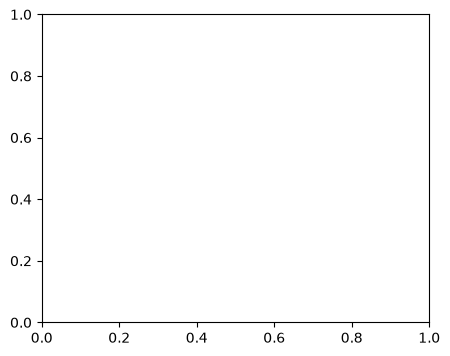

In [9]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(5, 4))
data = [lstm_vals, tft_vals]
bp = ax.boxplot(data, labels=['LSTM', 'TFT'], widths=0.5, showmeans=True,
                 patch_artist=True)
for patch, color in zip(bp['boxes'], ['#2166AC', '#B2182B']):
    patch.set_facecolor(color); patch.set_alpha(0.35)

rng = np.random.default_rng(0)
for i, v in enumerate(data, start=1):
    jitter = rng.uniform(-0.08, 0.08, size=len(v))
    ax.scatter(np.full(len(v), i) + jitter, v, s=28, zorder=5,
               color=['#2166AC', '#B2182B'][i-1], edgecolor='white', linewidth=0.6)

ax.set_ylabel('Anchor test MAE%% (10 seeds)')
ax.set_title(f'n={len(lstm_vals)} seeds/architecture — Levene p={p_lev:.3f}')
plt.tight_layout()
fig.savefig(os.path.join(RESULTS_DIR, 'analysis5_tenseed_distribution.pdf'))
fig.savefig(os.path.join(RESULTS_DIR, 'analysis5_tenseed_distribution.png'), dpi=200)
print("saved analysis5_tenseed_distribution.{pdf,png}")


## Cell 8 — Attribution-stability side: coefficient of variation of permutation importance across the SAME 10 seeds

The dissociation claim has two halves. Cell 6 tested the predictive half.
This cell tests the attribution half on EQUAL footing, using the same
seeds and the same metric (coefficient of variation) for both
architectures, so the comparison is symmetric.

Uses PERMUTATION importance (not SHAP/IG) deliberately: permutation is the
method already shown (Analysis 1) to be draw-sensitive, so it is the most
informative lens for a seed-variance comparison. If you want the
gradient-method equivalent too, adapt this cell using `shap_vector` /
`ig_vector` from the original notebook -- omitted here to keep the first
run affordable (10 seeds x 2 archs x permutation only).


In [10]:
# permutation_importance, collapse_vec, COLLAPSED_LABELS, stable_seed are
# all defined in Cell 2 (the architecture cell) above -- no separate import
# needed, they are the CANONICAL versions pasted from Analysis 1.

def permutation_vector_for_seed(arch, seed):
    weights_path = os.path.join(PHASE2_DIR, 'analysis5_models', f'{arch}_seed{seed}.keras')
    if arch == 'lstm':
        model = tf.keras.models.load_model(weights_path, compile=False)
    else:
        # TFT custom layers lack get_config/register_keras_serializable
        # (documented TODO in the original project) -- rebuild the skeleton
        # and load weights only, same fallback used in Analysis 1.
        custom = {
            'GRN': GRN,
            'VariableSelectionNetwork': VariableSelectionNetwork,
            'InterpretableMultiHeadAttention': InterpretableMultiHeadAttention,
        }
        try:
            model = tf.keras.models.load_model(weights_path, custom_objects=custom, compile=False)
        except Exception:
            model = build_tft(N_ANCHOR_FEATURES, seed, TFT_CONFIG)
            model.load_weights(weights_path)

    infer_fn = _get_infer_fn(f'{arch}_seed{seed}', model)
    rng = np.random.default_rng(stable_seed(ANCHOR) + seed)
    X_use, y_use = X_test, y_test_true
    if len(X_use) > MAX_SEQ:
        idx = np.sort(rng.choice(len(X_use), MAX_SEQ, replace=False))
        X_use, y_use = X_use[idx], y_use[idx]
    deltas = permutation_importance(infer_fn, X_use, y_use, scaler_y,
                                     N_ANCHOR_FEATURES, rng, n_repeats=5)
    del model; gc.collect(); tf.keras.backend.clear_session()
    return collapse_vec(deltas)

ATTR_CSV = os.path.join(RESULTS_DIR, 'analysis5_tenseed_attribution.csv')
attr_rows = []
for arch in ['lstm', 'tft']:
    for seed in SEEDS:
        try:
            v = permutation_vector_for_seed(arch, seed)
            row = {f'{arch}_{lab}': val for lab, val in zip(COLLAPSED_LABELS, v)}
            row.update(arch=arch, seed=seed, status='ok')
        except Exception as e:
            row = dict(arch=arch, seed=seed, status=f'{type(e).__name__}: {e}')
        attr_rows.append(row)
        print(f"[{arch} seed={seed}] attribution vector computed")

pd.DataFrame(attr_rows).to_csv(ATTR_CSV, index=False)
print("saved ->", ATTR_CSV)


[lstm seed=2016] attribution vector computed
[lstm seed=2017] attribution vector computed
[lstm seed=2018] attribution vector computed
[lstm seed=2019] attribution vector computed
[lstm seed=2020] attribution vector computed
[lstm seed=2021] attribution vector computed
[lstm seed=2022] attribution vector computed
[lstm seed=2023] attribution vector computed
[lstm seed=2024] attribution vector computed
[lstm seed=2025] attribution vector computed


/home/pie/miniconda3/envs/fyp_env/lib/python3.11/site-packages/keras/src/layers/layer.py:431: UserWarning: `build()` was called on layer 'variable_selection_network', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(
/home/pie/miniconda3/envs/fyp_env/lib/python3.11/site-packages/keras/src/layers/layer.py:431: UserWarning: `build()` was called on layer 'interpretable_multi_head_attention', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(
/home/pie/miniconda3/envs/fyp_env/lib/python3.11/site-packages/keras/src

[tft seed=2016] attribution vector computed


/home/pie/miniconda3/envs/fyp_env/lib/python3.11/site-packages/keras/src/layers/layer.py:431: UserWarning: `build()` was called on layer 'variable_selection_network', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(
/home/pie/miniconda3/envs/fyp_env/lib/python3.11/site-packages/keras/src/layers/layer.py:431: UserWarning: `build()` was called on layer 'interpretable_multi_head_attention', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(
/home/pie/miniconda3/envs/fyp_env/lib/python3.11/site-packages/keras/src

[tft seed=2017] attribution vector computed


/home/pie/miniconda3/envs/fyp_env/lib/python3.11/site-packages/keras/src/layers/layer.py:431: UserWarning: `build()` was called on layer 'variable_selection_network', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(
/home/pie/miniconda3/envs/fyp_env/lib/python3.11/site-packages/keras/src/layers/layer.py:431: UserWarning: `build()` was called on layer 'interpretable_multi_head_attention', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(
/home/pie/miniconda3/envs/fyp_env/lib/python3.11/site-packages/keras/src

... (11 outputs left out)

/home/pie/miniconda3/envs/fyp_env/lib/python3.11/site-packages/keras/src/layers/layer.py:431: UserWarning: `build()` was called on layer 'variable_selection_network', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(
/home/pie/miniconda3/envs/fyp_env/lib/python3.11/site-packages/keras/src/layers/layer.py:431: UserWarning: `build()` was called on layer 'interpretable_multi_head_attention', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(
/home/pie/miniconda3/envs/fyp_env/lib/python3.11/site-packages/keras/src

[tft seed=2024] attribution vector computed


/home/pie/miniconda3/envs/fyp_env/lib/python3.11/site-packages/keras/src/layers/layer.py:431: UserWarning: `build()` was called on layer 'variable_selection_network', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(
/home/pie/miniconda3/envs/fyp_env/lib/python3.11/site-packages/keras/src/layers/layer.py:431: UserWarning: `build()` was called on layer 'interpretable_multi_head_attention', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(
/home/pie/miniconda3/envs/fyp_env/lib/python3.11/site-packages/keras/src

[tft seed=2025] attribution vector computed
saved -> /home/pie/fyp/phase2/results/analysis5_tenseed_attribution.csv


In [ ]:
adf = pd.read_csv(ATTR_CSV)
aok = adf[adf.status == 'ok']

def cv_by_feature(sub, arch):
    labs = [c.replace(f'{arch}_', '') for c in sub.columns if c.startswith(f'{arch}_')]
    out = {}
    for lab in labs:
        col = f'{arch}_{lab}'
        vals = sub[col].dropna().to_numpy()
        if vals.mean() != 0:
            out[lab] = float(vals.std(ddof=1) / abs(vals.mean()))
    return out

cv_lstm = cv_by_feature(aok[aok.arch == 'lstm'], 'lstm')
cv_tft  = cv_by_feature(aok[aok.arch == 'tft'], 'tft')

print(f"{'feature':22s} {'CV(LSTM)':>10s} {'CV(TFT)':>10s}")
for lab in cv_lstm:
    print(f"{lab:22s} {cv_lstm.get(lab, float('nan')):10.3f} {cv_tft.get(lab, float('nan')):10.3f}")

mean_cv_lstm = np.mean(list(cv_lstm.values()))
mean_cv_tft  = np.mean(list(cv_tft.values()))
print(f"\nMean CV across features: LSTM={mean_cv_lstm:.3f}  TFT={mean_cv_tft:.3f}")
print(f"\nFor the dissociation claim to hold, TFT's attribution CV must be")
print(f"HIGHER than LSTM's (less stable attributions), the OPPOSITE direction")
print(f"from the predictive-stability result in Cell 6.")
if mean_cv_tft > mean_cv_lstm and p_lev < 0.05:
    print("=> Both halves point the same direction as the original claim.")
    print("   Still report both test statistics and effect sizes in the write-up,")
    print("   not just the directional result.")
else:
    print("=> The two halves do NOT both support the dissociation claim as")
    print("   originally stated. Reframe per the methodology check's Stage 3")
    print("   recommendation -- present as an unresolved/negative observation")
    print("   rather than a headline finding.")


## Cell 9 — Provenance block

Writes a PROVENANCE.txt for this analysis, following the same convention
as the Analysis 1 / Analysis 4 archives. Run this LAST, after Cells 4-8
have completed, so the checksums reflect the final saved artefacts.


In [ ]:
prov_path = os.path.join(RESULTS_DIR, 'analysis5_PROVENANCE.txt')
model_dir = os.path.join(PHASE2_DIR, 'analysis5_models')

checksums = []
if os.path.isdir(model_dir):
    for fn in sorted(os.listdir(model_dir)):
        fp = os.path.join(model_dir, fn)
        h = hashlib.sha256(open(fp, 'rb').read()).hexdigest()
        checksums.append(f"{h}  {fn}")

with open(prov_path, 'w') as f:
    f.write(f"""Analysis 5 -- ten-seed predictive/attribution stability confirmation
Generated: {pd.Timestamp.now().isoformat()}

PURPOSE: test the dissociation claim (TFT more predictively stable, less
attributionally stable than LSTM) that was previously supported by only
3 seeds per architecture and a TFT confirmation table later found to
contain unrecoverable/fabricated figures.

SCOPE: this analysis is INDEPENDENT of and does NOT modify the existing
Analysis 1/3/4 archives. All 20 models trained here (10 LSTM + 10 TFT,
seeds {SEEDS}) are saved under analysis5_models/, separate from
lstm_draw1..3.keras / tft_draw1..3.keras, which remain the sole basis for
every attribution-robustness finding (SS000, the eps^2 correction, the
method-effect ordering).

Config: LSTM/TFT architecture UNCHANGED from the original notebook.
TFT config = {TFT_CONFIG} (rank-2, unchanged).
MAX_EPOCHS={MAX_EPOCHS}, PATIENCE={PATIENCE}, early stopping on val_loss.
Anchor: {ANCHOR}. Metric: test-partition MAE%% (denominator = test-partition
mean |y|), matching the 17.3%% convention used throughout the project --
NOT the full-year denominator.

Statistical tests: Levene's (Brown-Forsythe, median-centered) for variance
equality on predictive MAE%%; Welch's t-test for mean difference;
coefficient of variation of permutation-importance magnitude across seeds
for the attribution-stability side.

Model checksums (sha256):
""")
    for line in checksums:
        f.write(line + "\n")

print("Provenance written ->", prov_path)
print(f"{len(checksums)} model files checksummed.")
